# 08 · Events on the price charts

**Milestone 3, item 3.2** · see `docs/MILESTONES.md`

## What we're looking for

Notebook 07 showed *how* prices moved. This notebook adds *what was happening* at the
time: the 16 events in `data/processed/events.csv` (item 3.1, reviewed and approved).

We want a first, visual answer to three questions:
1. Which events line up with a jump in a meat's price, and which don't?
2. Do the **popular explanations** (food plant fires, Colorado bird-flu culls, the
   cage-free egg law) line up with anything in the price data?
3. For beef, how do the events fit the drought → sell-off → herd → price chain?

This is still **exploratory**: lining things up on a chart can suggest a link, but it
can't prove one. Milestone 4 tests the strongest candidates properly.

**Sections**
1. The event list
2. All events on one timeline
3. Each meat's price with its events
4. How much did prices move around each event?
5. Beef: the events on the supply chain
6. What we found, and what's next

## Reading guide (no statistics background needed)

**What this notebook does:** it puts 16 dated events (plant closures, droughts, disease
outbreaks, trade decisions and three popular claims) on the price charts, to see which
ones line up with price jumps.

**Words you'll see:**
- **Real price / after inflation:** the price compared with prices in general. A rise
  "after inflation" means the item got more expensive *relative to everything else*.
- **Shaded band / vertical line:** a shaded band is an event that lasted a while; a thin
  line is a one-day event. Dashed or faded marks are popular claims being checked.
- **Rank of 100 (section 4):** how a price change compares with every other three-month
  change since 2015. A rank of 95 means only 5 in 100 periods saw a bigger rise; 50 is an
  ordinary period.
- **Popular claim:** an explanation people often repeat, included so it can be checked.

**Keep in mind:** lining things up on a chart can *suggest* a link but can't prove one.
Notebook 11 tests the events properly.

**If you only read one part:** section 6, *What we found*.

**Want the whole project in plain language?** See *Findings and methods explained*: `docs/FINDINGS.md` in the repo, or **Docs** in the bar at the top of the project site.

## Setup

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from dotenv import find_dotenv

env_path = find_dotenv()
PROJECT_ROOT = Path(env_path).parent if env_path else Path.cwd().parent
PROCESSED = PROJECT_ROOT / "data" / "processed"
df = pd.read_csv(PROCESSED / "master_monthly.csv", parse_dates=["date"]).set_index("date")
events = pd.read_csv(PROCESSED / "events.csv", parse_dates=["start_date", "end_date"])

MEATS = {"beef": "Ground beef", "pork": "Pork chops", "chicken": "Chicken breast"}
COLORS = {"beef": "#9A3B2E", "pork": "#2F6690", "chicken": "#C08A1E"}
# One color per kind of event, chosen so they don't clash with the meat colors
CATEGORY_COLORS = {
    "weather": "#D9A441", "packing_capacity": "#7A4E9C", "feed_costs": "#3C8D5A",
    "disease": "#D1495B", "trade": "#E07B39", "data": "#9E9E9E", "popular_claim": "#555555",
}
CATEGORY_NAMES = {
    "weather": "Weather (drought)", "packing_capacity": "Packing plants", "feed_costs": "Feed costs",
    "disease": "Animal disease", "trade": "Trade", "data": "Data gap", "popular_claim": "Popular claim",
}
BASE_MONTH = df["cpi_all_items"].last_valid_index()
prices = df.loc["2015":]
LATEST = prices.index.max()

events["meat_list"] = events["meats"].str.split(";")
events["is_claim"] = events["popular_explanation"].eq("yes")
# A drought with no end date is still going on: run it to the latest month of data
ongoing_weather = events["category"].eq("weather") & events["end_date"].isna()
events.loc[ongoing_weather, "end_date"] = LATEST
# An event with an end date more than a month after it starts is drawn as a shaded band;
# anything else is drawn as a line on the day it started.
events["is_period"] = (events["end_date"] - events["start_date"]).dt.days > 31

print(f"{len(events)} events, {events['is_claim'].sum()} of them popular claims; "
      f"prices {prices.index.min():%b %Y} to {LATEST:%b %Y}, real prices in {BASE_MONTH:%B %Y} dollars")

16 events, 3 of them popular claims; prices Jan 2015 to Oct 2026, real prices in October 2026 dollars


## 1 · The event list

**What we're looking for:** a quick reminder of what's in the list before we chart it.
Each event has a kind (category), the meats it should affect, and what we'd expect to
see in the prices if it mattered.

In [2]:
pd.set_option("display.max_colwidth", 70)
events[["event_id", "start_date", "end_date", "event", "category", "meats", "popular_explanation"]] \
    .assign(start_date=lambda d: d["start_date"].dt.strftime("%Y-%m-%d"),
            end_date=lambda d: d["end_date"].dt.strftime("%Y-%m-%d").fillna("(none)")) \
    .set_index("event_id")

,start_date,end_date,event,category,meats,popular_explanation
event_id,,,,,,
E01,2011-01-01,2013-12-31,Drought in cattle country (2011-2013),weather,beef,no
E02,2019-08-09,2019-12-31,"Tyson beef plant fire, Holcomb, Kansas",packing_capacity,beef,no
E03,2020-04-01,2020-06-30,COVID-19 meatpacking plant closures,packing_capacity,beef;pork;chicken,no
E04,2020-07-01,2023-12-31,Drought in cattle country (2020-2023),weather,beef,no
E05,2021-05-30,2021-06-02,JBS ransomware cyberattack,packing_capacity,beef;pork,no
E06,2022-02-24,2022-12-31,Russia invades Ukraine; grain and feed prices surge,feed_costs,chicken;pork;beef,no
E07,2022-02-09,2022-12-31,Highly pathogenic bird flu outbreak (2022 wave),disease,chicken,no
E08,2022-04-01,2022-05-31,Fires at food processing plants (widely reported),popular_claim,chicken;beef;pork,yes
E09,2024-07-08,2024-07-31,Colorado bird-flu culls and disaster emergency (Weld County egg fa...,popular_claim,chicken,yes


In [3]:
print("Events per meat:", {m: int(events["meat_list"].apply(lambda l: m in l).sum()) for m in MEATS})

Events per meat: {'beef': 13, 'pork': 5, 'chicken': 7}


### How to read it
One row per event. **No end date** means the event happened on one day (a plant closing,
a law taking effect) or is still going on (the second Mexican cattle import suspension,
screwworm in Texas). Those are drawn as a line on the start date. The one exception is
the 2026 drought, which is still going on: the setup cell runs it to the latest month,
so it's drawn as a band like the other droughts.
**popular_explanation = yes** marks the three claims that are widely repeated but
weren't expected to move meat prices; they're in the list so we can check them against
the data.

### What it means
Beef has by far the most events (13 of 16), which fits: it's the meat whose price rose the most. Chicken has seven, and all three popular claims touch chicken. Pork has five, and every one of them is shared with another meat.

## 2 · All events on one timeline

**What we're looking for:** how the events spread out over time, and where they cluster.
Each bar is one event, colored by kind. Single-day events are shown as dots. The popular
claims have a dashed outline.

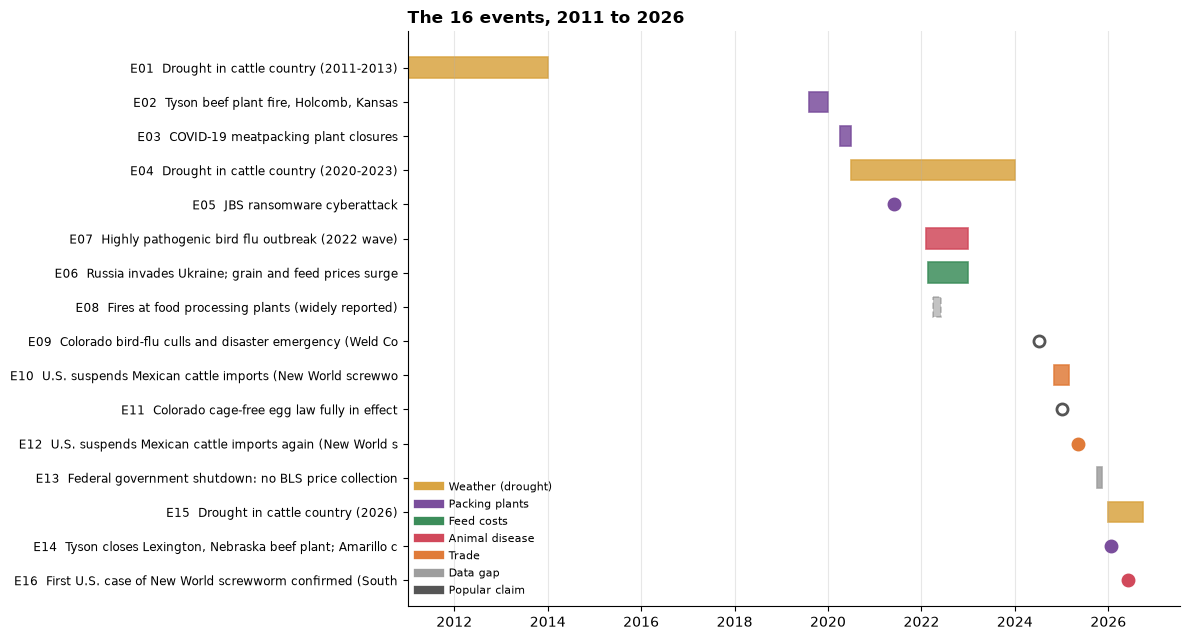

In [4]:
ev = events.sort_values("start_date").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 6.5))
for i, e in ev.iterrows():
    color = CATEGORY_COLORS[e["category"]]
    if e["is_period"]:
        ax.barh(i, e["end_date"] - e["start_date"], left=e["start_date"], height=0.6, color=color,
                alpha=0.35 if e["is_claim"] else 0.85, edgecolor=color, linewidth=1.2,
                linestyle="--" if e["is_claim"] else "-")
    else:
        ax.plot(e["start_date"], i, marker="o", markersize=8, color=color,
                markerfacecolor="white" if e["is_claim"] else color, markeredgewidth=2)
ax.set_yticks(range(len(ev)))
ax.set_yticklabels([f"{e['event_id']}  {e['event'][:55]}" for _, e in ev.iterrows()], fontsize=8.5)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="x", alpha=0.3)
handles = [plt.Line2D([], [], color=c, linewidth=6, label=CATEGORY_NAMES[k]) for k, c in CATEGORY_COLORS.items()]
ax.legend(handles=handles, loc="lower left", fontsize=8, frameon=False)
ax.set_title("The 16 events, 2011 to 2026", loc="left", fontweight="bold")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

### How to read it
Time runs left to right. Long bars are events that lasted months or years (droughts,
the COVID closures, the 2022 feed-cost surge); dots are single days. Faded bars and
hollow dots are the popular claims.

### What it means
The events fall into **two clusters**: 2020–2022 (COVID closures, the JBS attack, drought, the feed-cost surge, bird flu) and 2024–2026 (the Mexican cattle import suspensions, the Tyson plant closure, a new drought, screwworm). Between 2015 and 2019 there is only one event (the 2019 Tyson fire), and those are the same years prices were flat or falling.

The clustering is also the first warning for the analysis: in 2022, three events (feed costs, bird flu, the fires claim) start within two months of each other, so a price jump in 2022 could belong to any of them.

## 3 · Each meat's price with its events

**What we're looking for:** whether each meat's price jumps when its events happen.
Each chart shows one meat's price (as shoppers paid it at the time) with only the events
that should affect that meat. Events are numbered to match the list above; shaded bands
are events that lasted a while, lines are single days, dashed lines are popular claims.

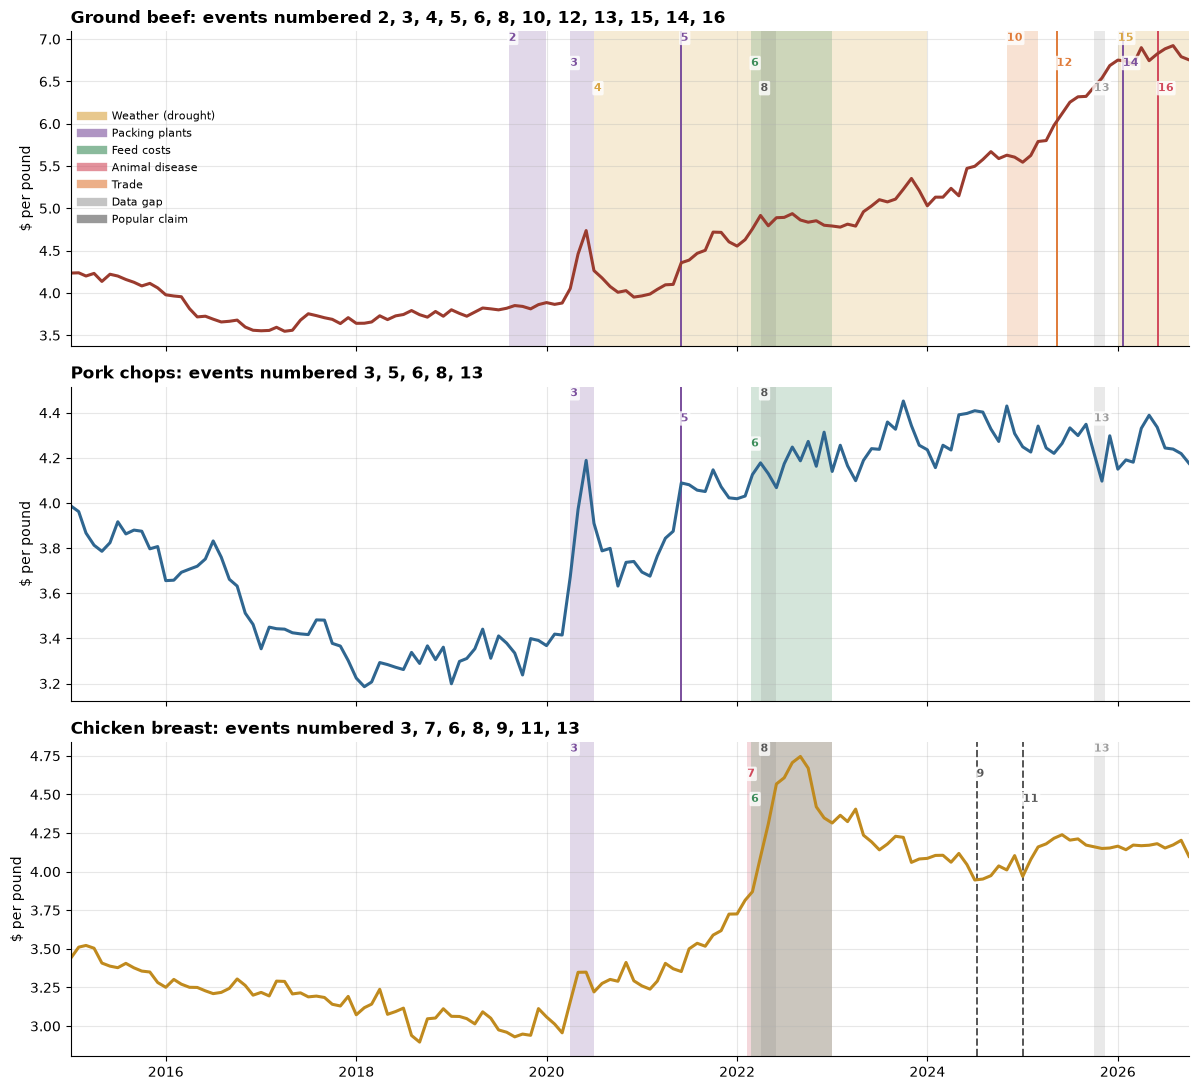

In [5]:
def draw_events(ax, meat=None, start=None, label=True):
    """Shade or mark the events that affect `meat` (all events if None) on a time axis."""
    start = start or prices.index.min()
    subset = events if meat is None else events[events["meat_list"].apply(lambda m: meat in m)]
    subset = subset[subset["start_date"] >= pd.Timestamp(start) - pd.DateOffset(years=3)]
    subset = subset.sort_values("start_date").reset_index(drop=True)
    heights = [0.97, 0.89, 0.81]
    for i, e in subset.iterrows():
        color = CATEGORY_COLORS[e["category"]]
        begin = max(e["start_date"], pd.Timestamp(start))
        if e["is_period"]:
            ax.axvspan(begin, min(e["end_date"], LATEST), color=color, alpha=0.12 if e["is_claim"] else 0.22,
                       linewidth=0)
        else:
            ax.axvline(begin, color=color, linewidth=1.4, linestyle="--" if e["is_claim"] else "-")
        if label:
            ax.text(begin, heights[i % 3], e["event_id"][1:].lstrip("0"), transform=ax.get_xaxis_transform(),
                    fontsize=8, fontweight="bold", color=color, ha="left",
                    bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.8))
    return subset


fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
for ax, (meat, name) in zip(axes, MEATS.items()):
    shown = draw_events(ax, meat)
    ax.plot(prices.index, prices[f"{meat}_price"], color=COLORS[meat], linewidth=2.2)
    ax.set_ylabel("$ per pound")
    ax.set_title(f"{name}: events numbered " + ", ".join(shown["event_id"].str[1:].str.lstrip("0")),
                 loc="left", fontweight="bold")
    ax.grid(alpha=0.3)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
ax.set_xlim(prices.index.min(), LATEST)
handles = [plt.Line2D([], [], color=c, linewidth=6, alpha=0.6, label=CATEGORY_NAMES[k])
           for k, c in CATEGORY_COLORS.items()]
axes[0].legend(handles=handles, loc="upper left", bbox_to_anchor=(0, 0.78), fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

### How to read it
The colored line is the price. Behind it, each event affecting that meat is a shaded
band (if it lasted more than a month) or a vertical line (a single day), with its number
at the top. Bands from before 2015 (the 2011–2013 drought) are cut off at the left edge,
because BLS prices in this project start in 2015.

### What it means
- **Ground beef:** the COVID closures (3) caused a sharp spike in spring 2020 that was gone by autumn. After that the price climbs **steadily** through the 2020–2023 drought (4), and the climb gets **steeper from late 2024**, when the herd was at its smallest and Mexican imports were suspended (10, 12). The one-day events (5 JBS, 14 Tyson closure, 16 screwworm) don't show up as clear steps; they sit on a rise that was already under way.
- **Pork chops:** the COVID spike (3) is the biggest jump in the pork series, and it faded within months too. Pork stepped up again in spring 2021 around the JBS attack (5) and has moved sideways since 2022, even through the feed-cost surge (6).
- **Chicken breast:** the big event is the **2022 spike**, which lines up with three events at once: the feed-cost surge (6), the bird flu wave (7) and the fires claim (8). The chart can't tell which one did it. The price fell back in 2023 as feed costs eased. Around the two Colorado claims (9 culls, 11 cage-free law) the price doesn't jump: it was drifting down at the culls and dipped briefly at the law.

## 4 · How much did prices move around each event?

**What we're looking for:** a number to go with each picture. For every event and every
meat it should affect, we compare the **inflation-adjusted price in the month before the
event started** with the price **three months after it started**.

On its own, a change like "+6% in three months" doesn't mean much, because prices move
around anyway. So we also compare each change with **every other three-month change**
for that meat since 2015, and report where it ranks: a rank of 95 means only 5% of
three-month periods saw a bigger rise.

This is a rough screen, not a test. A big move at an event could still be a coincidence,
and the method misses effects that build slowly (like drought). Milestone 4 handles
both.

In [6]:
HORIZON = 3  # months after the event starts

def three_month_changes(meat):
    """Percent change in the real price from month t-1 to month t+HORIZON, for every month t."""
    s = prices[f"{meat}_price_real"]
    return (s.shift(-HORIZON) / s.shift(1) - 1) * 100

rows = []
for _, e in events.iterrows():
    if e["category"] == "data":
        continue  # the shutdown didn't change prices; it only interrupted data collection
    month = e["start_date"].to_period("M").to_timestamp()
    for meat in e["meat_list"]:
        changes = three_month_changes(meat)
        if month not in changes.index or pd.isna(changes.loc[month]):
            continue  # before 2015, or too recent to have three months after
        change = changes.loc[month]
        rows.append({
            "event_id": e["event_id"], "event": e["event"][:48], "meat": meat,
            "popular_claim": e["popular_explanation"],
            "real_change_pct": round(change, 1),
            "rank_of_100": round((changes.dropna() < change).mean() * 100),
        })
moves = pd.DataFrame(rows).set_index("event_id")
moves

,event,meat,popular_claim,real_change_pct,rank_of_100
event_id,,,,,
E02,"Tyson beef plant fire, Holcomb, Kansas",beef,no,0.1,49
E03,COVID-19 meatpacking plant closures,beef,no,9.5,97
E03,COVID-19 meatpacking plant closures,pork,no,14.1,98
E03,COVID-19 meatpacking plant closures,chicken,no,8.5,95
E04,Drought in cattle country (2020-2023),beef,no,-16.2,0
E05,JBS ransomware cyberattack,beef,no,6.5,92
E05,JBS ransomware cyberattack,pork,no,3.0,90
E06,Russia invades Ukraine; grain and feed prices su,chicken,no,11.3,96
E06,Russia invades Ukraine; grain and feed prices su,pork,no,-1.2,49


In [7]:
typical = pd.DataFrame({m: three_month_changes(m).abs().describe(percentiles=[0.5, 0.9])[["50%", "90%"]]
                        for m in MEATS}).round(1)
typical.index = ["Typical move (median, %)", "Big move (top 10%, %)"]
print("Size of three-month real price moves since 2015, up or down:")
typical

Size of three-month real price moves since 2015, up or down:


,beef,pork,chicken
"Typical move (median, %)",2.1,2.0,2.4
"Big move (top 10%, %)",6.7,6.0,6.2


### How to read it
**real_change_pct** is how much the inflation-adjusted price changed from the month
before the event to three months after it started. **rank_of_100** places that change
among all three-month changes for that meat since 2015: near 100 means one of the
biggest rises on record, near 50 means an ordinary period, near 0 means one of the
biggest falls. The second table gives a sense of scale: how big a typical three-month
move is, and how big the top 10% are.

Events that started before 2015 (the 2011–2013 drought) or too recently to have three
months of prices after them don't appear.

### What it means
A **typical** three-month move is about 2% either way; a **big** one (top 10%) is 6–7%.

**Moves that stand out (rank 90 or more):**
- **COVID plant closures (E03):** among the biggest moves on record for all three meats (beef +9.5%, pork +14.1%, chicken +8.6%; ranks 95–98). The clearest event effect in the data.
- **Chicken in 2022:** the feed-cost surge and bird flu (E06, E07) both show +11.3% (rank 96), and the fires claim (E08) +15.5% (rank 99). These three windows overlap, so they measure the same spike three times. One clue: the fires claim covered all three meats, but beef (−0.2%) and pork (−1.8%) didn't move, which points to something specific to chicken (feed, disease) rather than plant fires. That matches the fact-checkers.
- **JBS attack (E05):** beef +6.5% (rank 92), pork +3.0% (rank 90). High, but it falls inside the 2021 climb, so part of it would have happened anyway.
- **Second Mexican import suspension (E12):** beef +7.8% (rank 96). Beef was rising all through 2025, though, so almost any three-month stretch that year ranks high. This screen can't separate an event from a trend it lands on; Milestone 4 can.

**Ordinary months (rank 40–70):** the 2019 Tyson fire, the Colorado culls and cage-free law, the first import suspension, the 2026 Tyson closure, the screwworm case and the 2026 drought. None of them moved the price more than a normal month.

**A misleading number:** the 2020–2023 drought (E04) shows −16.2%, the biggest fall on record. That's not the drought; the band starts in July 2020, right as the COVID spike was unwinding, so the window measures the spike fading. Drought acts slowly, through the herd, which is what the next chart shows.

## 5 · Beef: the events on the supply chain

**What we're looking for:** most beef events don't act on price directly; they act on
the cattle supply first. This chart puts the beef events on the same timeline as
drought, the cow sell-off, and the inflation-adjusted beef price, starting in 2010 so
the earlier drought cycle is included.

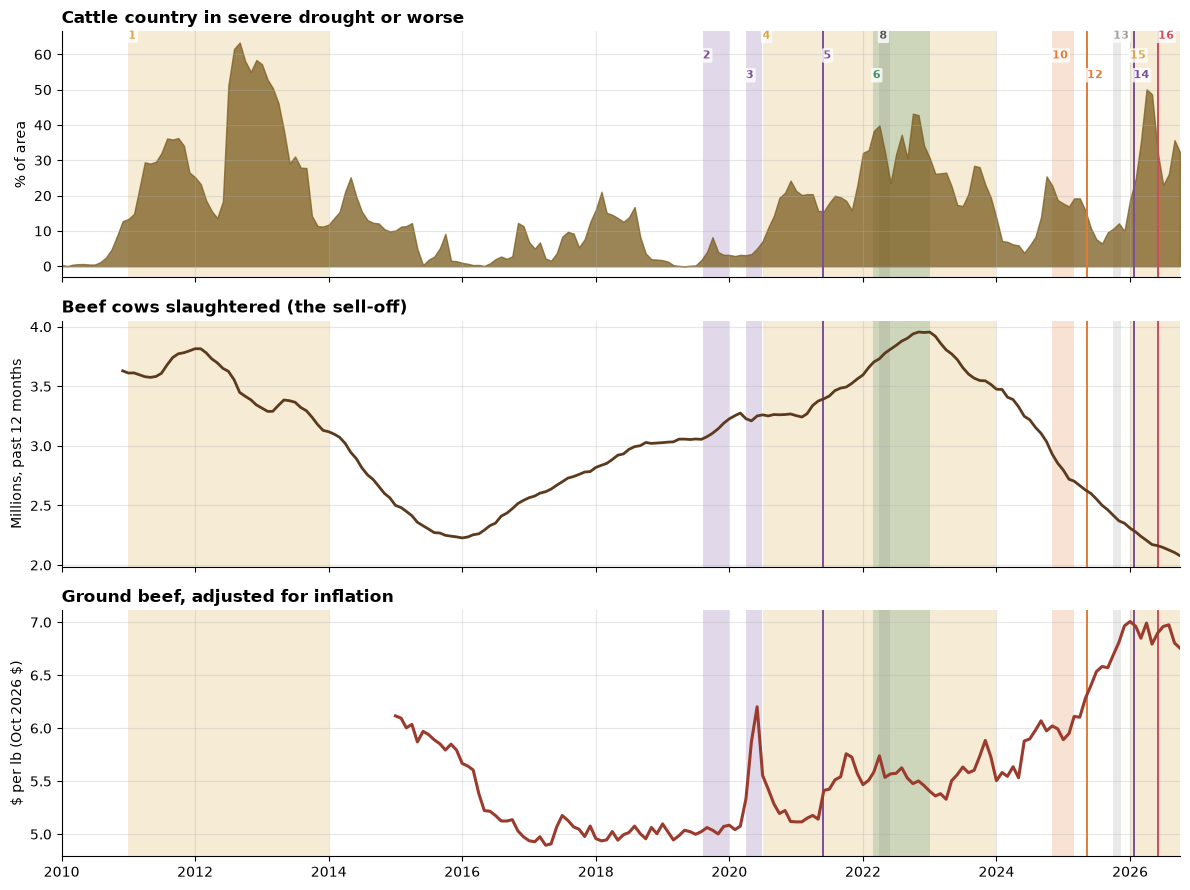

In [8]:
chain = df.loc["2010":]
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

draw_events(axes[0], "beef", start="2010-01-01")
axes[0].fill_between(chain.index, chain["drought_cattle_d2_plus_pct"], color="#7A5C1E", alpha=0.75)
axes[0].set_ylabel("% of area")
axes[0].set_title("Cattle country in severe drought or worse", loc="left", fontweight="bold")

draw_events(axes[1], "beef", start="2010-01-01", label=False)
axes[1].plot(chain.index, chain["slaughter_beef_cows_slaughtered_12mo"] / 1e6, color="#5B3A1E", linewidth=2)
axes[1].set_ylabel("Millions, past 12 months")
axes[1].set_title("Beef cows slaughtered (the sell-off)", loc="left", fontweight="bold")

draw_events(axes[2], "beef", start="2010-01-01", label=False)
axes[2].plot(chain.index, chain["beef_price_real"], color=COLORS["beef"], linewidth=2.2)
axes[2].set_ylabel(f"$ per lb ({BASE_MONTH:%b %Y} $)".replace("$", r"\$"))
axes[2].set_title("Ground beef, adjusted for inflation", loc="left", fontweight="bold")

for ax in axes:
    ax.grid(alpha=0.3)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[2].set_xlim(chain.index.min(), LATEST)
fig.tight_layout()
plt.show()

### How to read it
All three panels share the same time axis and the same beef events (numbers on the top
panel only). Read down a column: drought on top, then how many beef cows went to
slaughter, then the real beef price.

### What it means
Reading down each column shows the chain in both drought cycles:

- **2011–2013:** severe drought covered up to 63% of cattle country, and cow slaughter peaked in 2012. The BLS prices in this project start in 2015, at the tail of that cycle: the real beef price was high in 2015 and fell through 2017 as slaughter dropped and the herd rebuilt.
- **2020–2023:** drought returned, and cow slaughter rose to its highest level in early 2023. The real beef price climbed, but its steepest rise came **after** the drought band ended (2024–2026), as slaughter fell and the smaller herd meant fewer cattle to sell. The price follows the herd, with a delay.
- **The events in between** (packing plants, trade, screwworm) land on top of that slow rise. Some may have added to it, but none changes its direction.
- **2026:** drought is back and nearly as widespread as 2022 (about 50% at its peak), but cow slaughter keeps falling. Two possible reasons for Milestone 4 to check: so few cows are left that there's little to sell, or high cattle prices make ranchers hold on to them.

## 6 · What we found

1. **Short, sharp shocks are easy to see.** The 2020 COVID plant closures produced one of the biggest three-month price moves on record for all three meats, and in each case the jump faded within months.
2. **Chicken's 2022 spike lines up with feed costs and bird flu**, which started at the same time, so the charts can't say which mattered more. The spike faded as feed costs eased in 2023.
3. **The popular claims don't hold up.** The Colorado culls and the cage-free egg law came during ordinary months for chicken prices. The plant-fires claim lines up with chicken's 2022 spike, but beef and pork didn't move at the same time, which points to a chicken-specific cause.
4. **Beef's rise is a slow build, not a series of shocks.** It follows the drought → sell-off → smaller herd chain with a delay of a year or more. The single events (JBS, import suspensions, the Tyson closure, screwworm) sit on a climb that was already under way, and none of them stands out from it.
5. **This screen has limits:** overlapping events can't be separated, a rising trend makes any event during it look big, and slow effects like drought don't show up in a three-month window. That's what Milestone 4 is for.

## What's next and why

**Milestone 4: testing what the charts suggest.** Lining events up with prices is a
good first screen, but it can't separate an event's effect from everything else going
on at the same time. Milestone 4 does that:

- **Item 4.3 (event tests):** checks whether each meat's price really shifted at the
  events that stood out here, using the months before each event to predict what would
  have happened without it.
- **Item 4.4 (the supply chain):** measures how much drought raises cow slaughter and
  how much a smaller herd raises the real beef price, which the event lines can't do
  on their own.
- **Items 4.1, 4.2, 4.5:** beef vs. inflation, who gets the beef dollar, and the final
  "are today's prices justified?" verdict.

The event list and the `draw_events` approach used here will also go into the app
(Milestone 5), so readers can turn events on and off on each chart.